# Autoregressive Text Generation

ICT4403 — Assignment 2

Compare RNN, BiRNN, LSTM and GRU on Alice’s Adventures in Wonderland. Run all cells from this notebook’s directory after installing requirements.txt. Training uses CPU for a reproducible shared device. Outputs are overwritten when rerun.

## Data and experimental design

Gutenberg text is stripped of its license header/footer, lowercased and tokenized into words/contractions, numbers and punctuation. Contiguous 80:10:10 splits precede window construction; vocabulary uses training tokens appearing at least twice. Inputs contain 12 tokens; the next token is the label. No window crosses a split. All models use 64-dimensional embeddings, 128 hidden units per direction, Adam at 0.001, batch size 128, gradient clipping at 1 and 15 epochs. Lowest validation-loss checkpoints are tested. Equal dimensions do not imply equal parameter counts; counts are reported. BiRNN only reverses the observed prefix, never the unseen target.

In [1]:
"""Reproducible word-level recurrent language modelling experiment."""
from pathlib import Path
from collections import Counter
import copy
import hashlib
import json
import math
import os
import platform
import random
import re
import time
import urllib.request

os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib-cache'))

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path.cwd()
CONFIG = dict(seed=42, context=12, embedding=64, hidden=128, epochs=15,
              batch_size=128, learning_rate=0.001, min_frequency=2, threads=4)
URL = 'https://www.gutenberg.org/files/11/11-0.txt'
SEEDS = ['alice was beginning to get very tired of sitting by her sister',
         'the queen turned angrily away from him and said to the knave',
         'the mad hatter looked at alice and began to speak very slowly']


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)*|\d+|[^\w\s]", text.lower().replace('’', "'"))


def prepare():
    data = ROOT / 'data'
    data.mkdir(exist_ok=True)
    path = data / 'alice.txt'
    if not path.exists():
        urllib.request.urlretrieve(URL, path)
    raw = path.read_bytes()
    text = raw.decode('utf-8-sig')
    start = re.search(r'\*\*\* START OF .*?\*\*\*', text)
    end = re.search(r'\*\*\* END OF .*?\*\*\*', text)
    if not start or not end:
        raise ValueError('Expected Gutenberg boundaries were not found')
    tokens = tokenize(text[start.end():end.start()])
    a, b = int(len(tokens)*.8), int(len(tokens)*.9)
    splits = [tokens[:a], tokens[a:b], tokens[b:]]
    counts = Counter(splits[0])
    vocab = ['<unk>'] + sorted(w for w, n in counts.items() if n >= CONFIG['min_frequency'])
    lookup = {w: i for i, w in enumerate(vocab)}
    datasets = []
    stats = {}
    for name, split in zip(['train', 'validation', 'test'], splits):
        ids = torch.tensor([lookup.get(w, 0) for w in split], dtype=torch.long)
        windows = ids.unfold(0, CONFIG['context']+1, 1)
        datasets.append(TensorDataset(windows[:, :-1].contiguous(), windows[:, -1].contiguous()))
        stats[name] = dict(tokens=len(split), examples=len(windows), unknown_fraction=float((ids == 0).float().mean()))
    stats.update(total_tokens=len(tokens), vocabulary_size=len(vocab), source=URL,
                 sha256=hashlib.sha256(raw).hexdigest(), split_policy='contiguous 80:10:10, split before windowing')
    (ROOT/'dataset_stats.json').write_text(json.dumps(stats, indent=2))
    (ROOT/'vocabulary.json').write_text(json.dumps(vocab, ensure_ascii=False), encoding='utf-8')
    return datasets, vocab, lookup, stats


class LanguageModel(nn.Module):
    def __init__(self, kind, size):
        super().__init__()
        self.embedding = nn.Embedding(size, CONFIG['embedding'])
        cls = {'RNN': nn.RNN, 'BiRNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind]
        self.recurrent = cls(CONFIG['embedding'], CONFIG['hidden'], batch_first=True,
                             bidirectional=kind == 'BiRNN')
        self.output = nn.Linear(CONFIG['hidden']*(2 if kind == 'BiRNN' else 1), size)
        self.kind = kind

    def forward(self, x):
        _, state = self.recurrent(self.embedding(x))
        hidden = state[0] if self.kind == 'LSTM' else state
        # Both final directional states summarize only the observed 12-token prefix.
        features = torch.cat([hidden[-2], hidden[-1]], dim=1) if self.kind == 'BiRNN' else hidden[-1]
        return self.output(features)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, correct, count = 0., 0, 0
    for x, y in loader:
        logits = model(x)
        total += nn.functional.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return total/count, correct/count


@torch.no_grad()
def generate(model, seed, temperature, vocab, lookup, rng_seed, length=60):
    model.eval()
    ids = [lookup.get(w, 0) for w in tokenize(seed)]
    if len(ids) < CONFIG['context']:
        raise ValueError('Seed must have at least 12 tokens')
    rng = torch.Generator().manual_seed(rng_seed)
    generated = []
    for _ in range(length):
        logits = model(torch.tensor([ids[-CONFIG['context']:]]))[0]/temperature
        # Suppress the unknown symbol for readable samples; evaluation remains unmasked.
        logits[0] = -torch.inf
        idx = torch.multinomial(logits.softmax(0), 1, generator=rng).item()
        ids.append(idx)
        generated.append(vocab[idx])
    text = ' '.join(generated)
    text = re.sub(r'\s+([.,!?;:])', r'\1', text)
    bigrams = list(zip(generated, generated[1:]))
    return text, len(set(generated))/len(generated), 1-len(set(bigrams))/len(bigrams)


def run():
    torch.set_num_threads(CONFIG['threads'])
    torch.use_deterministic_algorithms(True)
    random.seed(CONFIG['seed'])
    np.random.seed(CONFIG['seed'])
    datasets, vocab, lookup, stats = prepare()
    print(json.dumps(stats, indent=2), flush=True)
    (ROOT/'checkpoints').mkdir(exist_ok=True)
    records, history, samples = [], [], []
    val_loader = DataLoader(datasets[1], batch_size=256)
    test_loader = DataLoader(datasets[2], batch_size=256)
    for kind in ['RNN', 'BiRNN', 'LSTM', 'GRU']:
        torch.manual_seed(CONFIG['seed'])
        model = LanguageModel(kind, len(vocab))
        optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])
        loader = DataLoader(datasets[0], batch_size=CONFIG['batch_size'], shuffle=True,
                            generator=torch.Generator().manual_seed(CONFIG['seed']))
        best_loss, best_epoch, best_state = math.inf, 0, None
        start = time.perf_counter()
        for epoch in range(1, CONFIG['epochs']+1):
            model.train()
            total, count = 0., 0
            for x, y in loader:
                optimizer.zero_grad(set_to_none=True)
                loss = nn.functional.cross_entropy(model(x), y)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.)
                optimizer.step()
                total += loss.item()*len(y)
                count += len(y)
            val_loss, _ = evaluate(model, val_loader)
            history.append(dict(model=kind, epoch=epoch, train_loss=total/count, validation_loss=val_loss))
            if val_loss < best_loss:
                best_loss, best_epoch, best_state = val_loss, epoch, copy.deepcopy(model.state_dict())
            print(f'{kind} epoch {epoch:02d}: train={total/count:.4f} validation={val_loss:.4f}', flush=True)
        elapsed = time.perf_counter()-start
        model.load_state_dict(best_state)
        torch.save({'state_dict': best_state, 'config': CONFIG, 'kind': kind, 'vocabulary': vocab}, ROOT/'checkpoints'/f'{kind}.pt')
        test_loss, accuracy = evaluate(model, test_loader)
        records.append(dict(model=kind, test_loss=test_loss, test_perplexity=math.exp(test_loss),
                            test_accuracy=accuracy, training_seconds=elapsed, best_epoch=best_epoch,
                            best_validation_loss=best_loss, parameters=sum(p.numel() for p in model.parameters())))
        for seed_id, seed in enumerate(SEEDS):
            for temperature in [.5, 1., 1.5]:
                for replicate in range(3):
                    text, diversity, repetition = generate(model, seed, temperature, vocab, lookup, 1000+seed_id*10+replicate)
                    samples.append(dict(model=kind, seed_id=seed_id, seed=seed, temperature=temperature,
                                        replicate=replicate, generated_text=text, unique_token_ratio=diversity,
                                        repeated_bigram_ratio=repetition))
        pd.DataFrame(records).to_csv(ROOT/'model_comparison_results.csv', index=False)
        pd.DataFrame(history).to_csv(ROOT/'training_history.csv', index=False)
        pd.DataFrame(samples).to_csv(ROOT/'generated_text_samples.csv', index=False)
    diagnostics = pd.DataFrame(samples).groupby(['model', 'temperature'])[['unique_token_ratio', 'repeated_bigram_ratio']].agg(['mean', 'std'])
    diagnostics.columns = ['_'.join(c) for c in diagnostics.columns]
    diagnostics.to_csv(ROOT/'generation_diagnostics.csv')
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
    frame = pd.DataFrame(history)
    for ax, kind in zip(axes.flat, ['RNN', 'BiRNN', 'LSTM', 'GRU']):
        sub = frame[frame.model == kind]
        ax.plot(sub.epoch, sub.train_loss, label='Training')
        ax.plot(sub.epoch, sub.validation_loss, label='Validation')
        ax.set(title=kind, xlabel='Epoch', ylabel='Cross-entropy loss')
        ax.legend()
    fig.savefig(ROOT/'loss_curves.png', dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for kind in ['RNN', 'BiRNN', 'LSTM', 'GRU']:
        sub = diagnostics.loc[kind]
        for ax, metric, title in zip(axes, ['unique_token_ratio', 'repeated_bigram_ratio'], ['Token diversity', 'Repeated bigrams']):
            ax.errorbar(sub.index, sub[metric+'_mean'], yerr=sub[metric+'_std'], marker='o', capsize=3, label=kind)
            ax.set(title=title, xlabel='Temperature', ylabel='Ratio (mean ± sample SD)', xticks=[.5, 1., 1.5])
    axes[0].legend()
    fig.savefig(ROOT/'temperature_diversity.png', dpi=160)
    plt.close(fig)
    metadata = dict(config=CONFIG, python=platform.python_version(), torch=torch.__version__,
                    numpy=np.__version__, pandas=pd.__version__, platform=platform.platform(),
                    device='CPU', processor=platform.processor(), seeds=SEEDS,
                    note='Training time includes validation and best-state copies; excludes dataset preparation and generation.')
    (ROOT/'run_metadata.json').write_text(json.dumps(metadata, indent=2))
    print(pd.DataFrame(records).to_string(index=False), flush=True)
    return pd.DataFrame(records)




## Train and evaluate

Cross-entropy uses natural logarithms; perplexity is exp(loss). Accuracy includes punctuation and unknown tokens, so this is next-token accuracy for word-level tokenization. Timing includes validation. One fixed training seed is a limitation; generation repeats do not estimate training variance.

In [2]:
RETRAIN = False  # Set True to reproduce training; otherwise inspect saved measured results.
if RETRAIN or not (ROOT/'model_comparison_results.csv').exists():
    results = run()
else:
    results = pd.read_csv(ROOT/'model_comparison_results.csv')
    print('Displaying saved experiment results. Set RETRAIN=True for a new run.')
display(results)

Displaying saved experiment results. Set RETRAIN=True for a new run.


,model,test_loss,test_perplexity,test_accuracy,training_seconds,best_epoch,best_validation_loss,parameters
0,RNN,4.002777,54.749975,0.242006,55.765715,10,3.873167,280171
1,BiRNN,4.117938,61.432430,0.239660,108.051017,6,3.994219,474347
2,LSTM,3.938019,51.316851,0.261367,101.048348,11,3.812242,354667
3,GRU,3.957325,52.317183,0.257260,99.509235,8,3.809431,329835


## Temperature experiments

Three fixed prompts × three temperatures × three sampling repeats × four models = 108 continuations of 60 tokens. Unknown symbols are masked only during generation. Diagnostics are computed on continuation tokens, excluding prompts: unique-token ratio = distinct tokens / 60; repeated-bigram ratio = 1 − distinct bigrams / 59. Higher diversity does not establish coherence.

,model,temperature,unique_token_ratio_mean,unique_token_ratio_std,repeated_bigram_ratio_mean,repeated_bigram_ratio_std
0,BiRNN,0.5,0.557407,0.051445,0.161959,0.058167
1,BiRNN,1.0,0.790741,0.065676,0.020716,0.025108
2,BiRNN,1.5,0.894444,0.044096,0.005650,0.011985
3,GRU,0.5,0.557407,0.032394,0.201507,0.045985
4,GRU,1.0,0.746296,0.046976,0.033898,0.023970
5,GRU,1.5,0.883333,0.050690,0.007533,0.008933
6,LSTM,0.5,0.553704,0.059382,0.177024,0.059389
7,LSTM,1.0,0.761111,0.049301,0.024482,0.025580
8,LSTM,1.5,0.862963,0.045474,0.007533,0.008933
9,RNN,0.5,0.585185,0.065851,0.137476,0.065339


,model,seed_id,seed,temperature,replicate,generated_text,unique_token_ratio,repeated_bigram_ratio
0,RNN,0,alice was beginning to get very tired of sitti...,0.5,0,"in a low tone, “ and they all crowded round th...",0.550000,0.169492
1,RNN,0,alice was beginning to get very tired of sitti...,0.5,1,in a minute or two and the march hare had been...,0.616667,0.101695
2,RNN,0,alice was beginning to get very tired of sitti...,0.5,2,", and the baby was busily to find herself, “ i...",0.633333,0.101695
3,RNN,0,alice was beginning to get very tired of sitti...,1.0,0,in a english tone; “ and they met now eagerly ...,0.850000,0.016949
4,RNN,0,alice was beginning to get very tired of sitti...,1.0,1,in a minute or two and if you ought had to be ...,0.850000,0.016949
...,...,...,...,...,...,...,...,...
103,GRU,2,the mad hatter looked at alice and began to sp...,1.0,1,among not; “ he took it doesn't people. ” “ no...,0.716667,0.033898
104,GRU,2,the mad hatter looked at alice and began to sp...,1.0,2,", with run say to see. “ i shall was at the to...",0.700000,0.067797
105,GRU,2,the mad hatter looked at alice and began to sp...,1.5,0,that solemnly back: his pebbles moved fountain...,0.933333,0.000000
106,GRU,2,the mad hatter looked at alice and began to sp...,1.5,1,among not deeply about out anything her voice;...,0.900000,0.000000


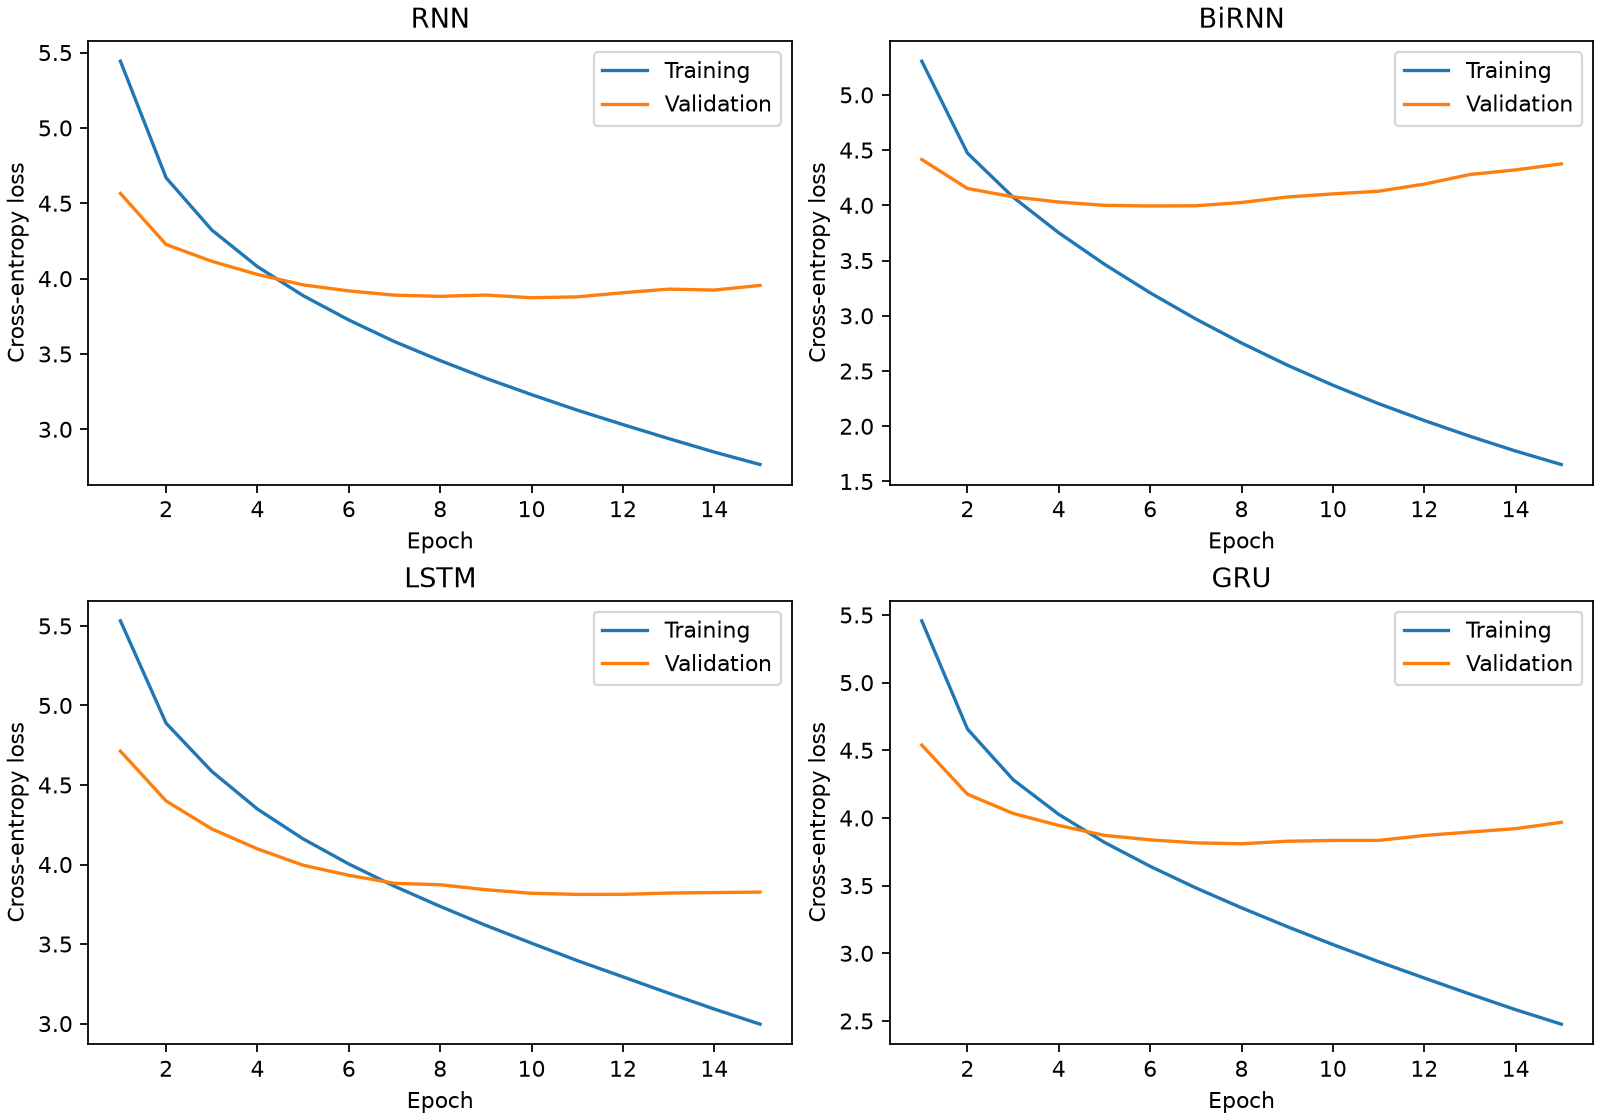

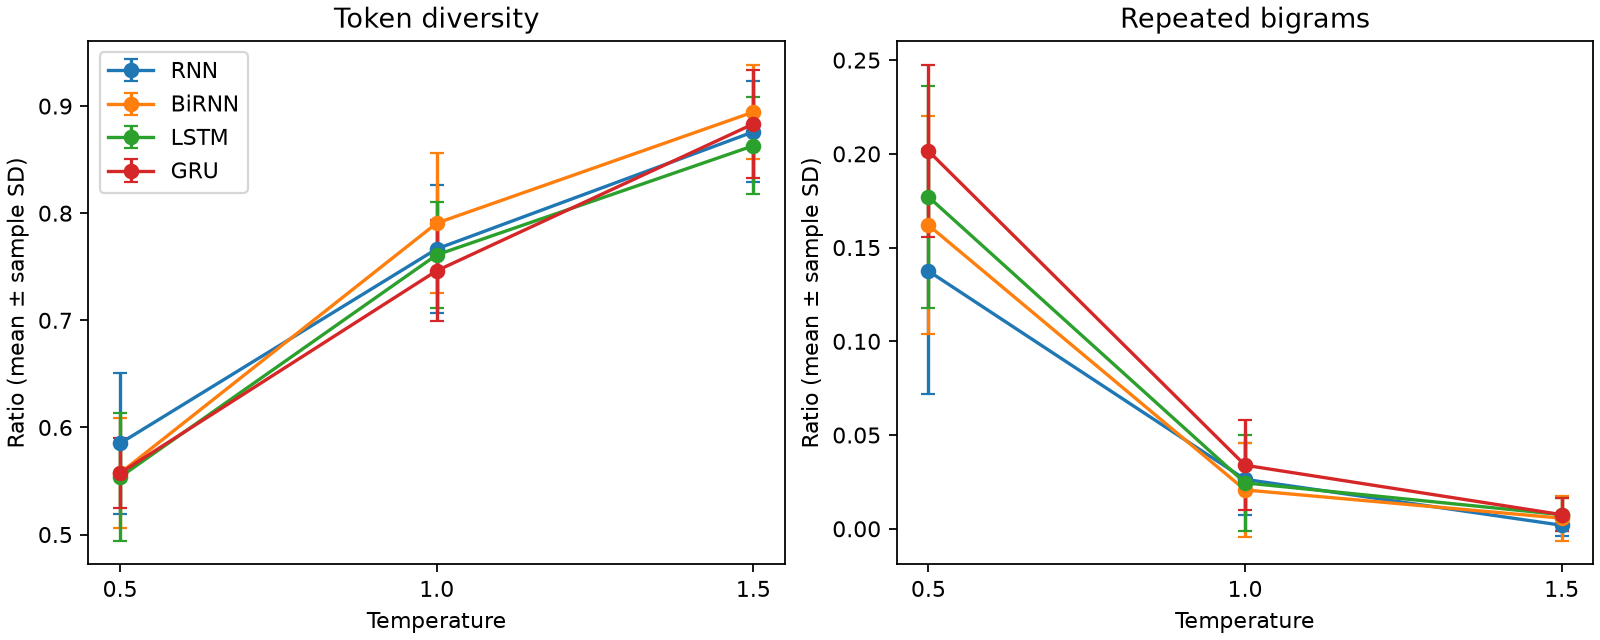

In [3]:
display(pd.read_csv('generation_diagnostics.csv'))
display(pd.read_csv('generated_text_samples.csv'))
from IPython.display import Image, display
display(Image(filename='loss_curves.png'))
display(Image(filename='temperature_diversity.png'))

## Interpretation

See README.md for the recorded experiment’s measured comparison and qualitative interpretation. Reruns can differ with package versions and hardware; compare regenerated CSVs before reusing conclusions.